### Laboratorium 3 - zadania

In [25]:
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from skimage.morphology import local_minima
from skimage.segmentation import mark_boundaries, slic

#### Zadanie 1

Dane są obrazy `tabby` i `caries` ([źródło](https://universe.roboflow.com/niu-workespeis/caries-xlrql/dataset/2)). Wykonaj dla nich segmentację przy użyciu algorytmu SLIC. Celem jest uzyskanie **jednolitych**  superpikseli, a więc zawierających tylko fragmenty obiektów lub tylko tła (a nie jednego i drugiego naraz). Przeanalizuj zachowanie algorytmu dla różnej liczby superpikseli i parametru sigma.

Zwróć uwagę, że wynikiem działania scikitowej implementacji SLIC - [`skimage.segmentation.slic`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.slic) - (podobnie jak wielu innych algorytmów klasyfikacyjnych) jest obraz typu `np.int64` przyporządkowujący każdemu pikselowi obrazu wejściowego indeks superpiksela. Takiej reprezentacji oczekuje też funkcja [`mark_boundaries`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.mark_boundaries).

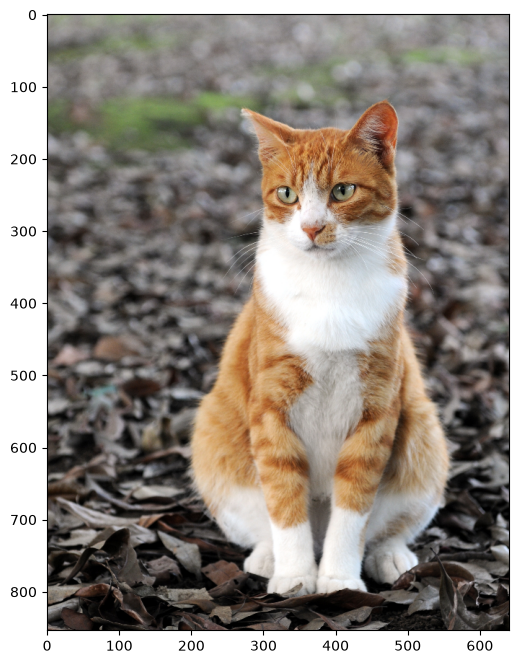

In [26]:
_ = cv2.imread('../Materialy/tabby.jpg')[..., ::-1]
tabby = cv2.resize(_, dsize=None, fx=0.3, fy=0.3)
plt.subplots(1,1,figsize=(8,8))[1].imshow(tabby);

Rozwiązanie:

Funkcja `badaj_slic` uruchamia SLIC osobno dla każdego zestawu parametrów z listy i rysuje wyniki w siatce (maks. 3 obrazy w wierszu). W tytule obrazka podana jest faktyczna liczba superpikseli – `n_segments` to tylko wartość przybliżona. Dla obrazu szarego (`caries`) funkcja sama ustawia `channel_axis=None`. Opcjonalny `wycinek=(y0, y1, x0, x1)` pozwala przybliżyć fragment obrazu (segmentacja i tak jest liczona dla całości).

In [27]:
def badaj_slic(img, tytul, lista_parametrow, wycinek=None, kolumny=3, szer=6):
    # lista_parametrow: [{parametr: wartość, ...}, ...] – każdy słownik to osobne wywołanie slic i osobny obrazek
    # wycinek: (y0, y1, x0, x1) – opcjonalne zbliżenie; segmentacja i tak liczona jest dla całego obrazu
    kanaly = -1 if img.ndim == 3 else None  # obraz szary (caries) -> channel_axis=None
    y0, y1, x0, x1 = wycinek or (0, img.shape[0], 0, img.shape[1])
    kolumny = min(kolumny, len(lista_parametrow))
    wiersze = int(np.ceil(len(lista_parametrow) / kolumny))
    wys = szer * (y1 - y0) / (x1 - x0) + 0.6  # + miejsce na tytuł
    _, axs = plt.subplots(wiersze, kolumny, figsize=(szer * kolumny, wys * wiersze + 0.5), squeeze=False, layout='constrained')
    for ax in axs.flat:
        ax.axis('off')
    for ax, parametry in zip(axs.flat, lista_parametrow):
        segmenty = slic(img, channel_axis=kanaly, **parametry)
        ax.imshow(mark_boundaries(img, segmenty)[y0:y1, x0:x1])
        opis = ', '.join(f'{k} = {v}' for k, v in parametry.items())
        ax.set_title(f'{opis}\nsuperpikseli: {len(np.unique(segmenty))}')
    plt.suptitle(tytul, fontsize=15, fontweight='bold')
    plt.show()

**Badanie 1: liczba superpikseli `n_segments`** – `sigma = 0` (domyślnie, bez rozmycia)

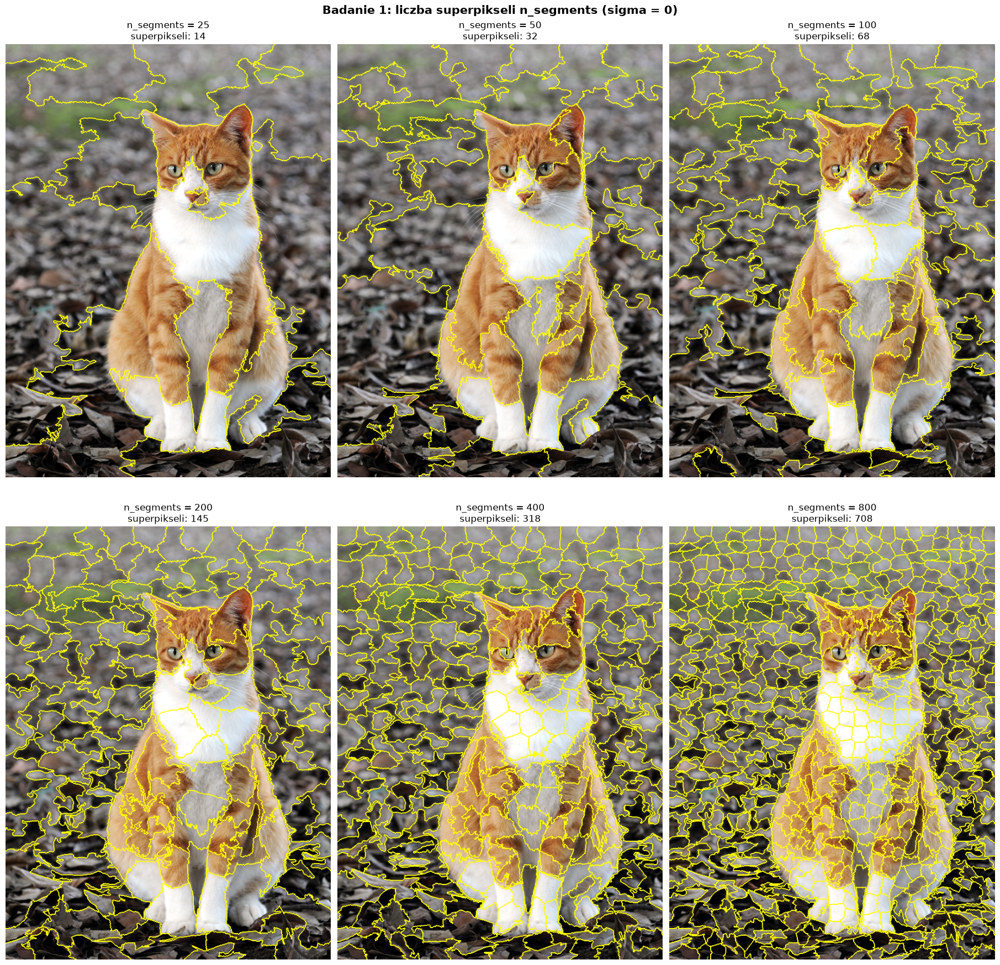

In [28]:
badaj_slic(tabby, 'Badanie 1: liczba superpikseli n_segments (sigma = 0)',
           [dict(n_segments=n) for n in [25, 50, 100, 200, 400, 800]])

**Badanie 2: `sigma`** – `n_segments = 200`

`sigma` to odchylenie standardowe filtru Gaussa (w pikselach), którym obraz jest rozmywany przed segmentacją. Domyślnie 0 – bez rozmycia.

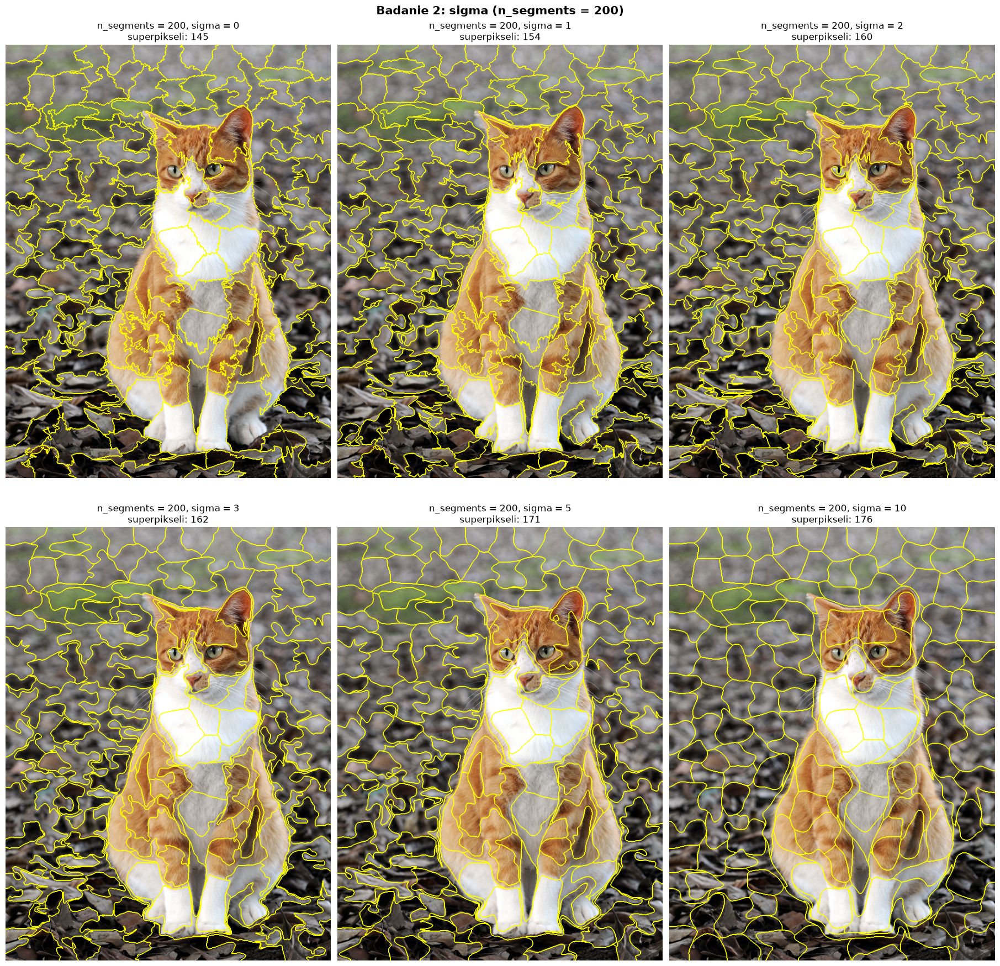

In [29]:
badaj_slic(tabby, 'Badanie 2: sigma (n_segments = 200)',
           [dict(n_segments=200, sigma=s) for s in [0, 1, 2, 3, 5, 10]])

**Badanie 3: `n_segments` × `sigma` – zbliżenie na dolną część kota** – tu krawędź kot/tło jest najtrudniejsza (białe łapy na jasnych liściach, pomarańczowe futro na brązowych liściach, ciemna szczelina między łapami).

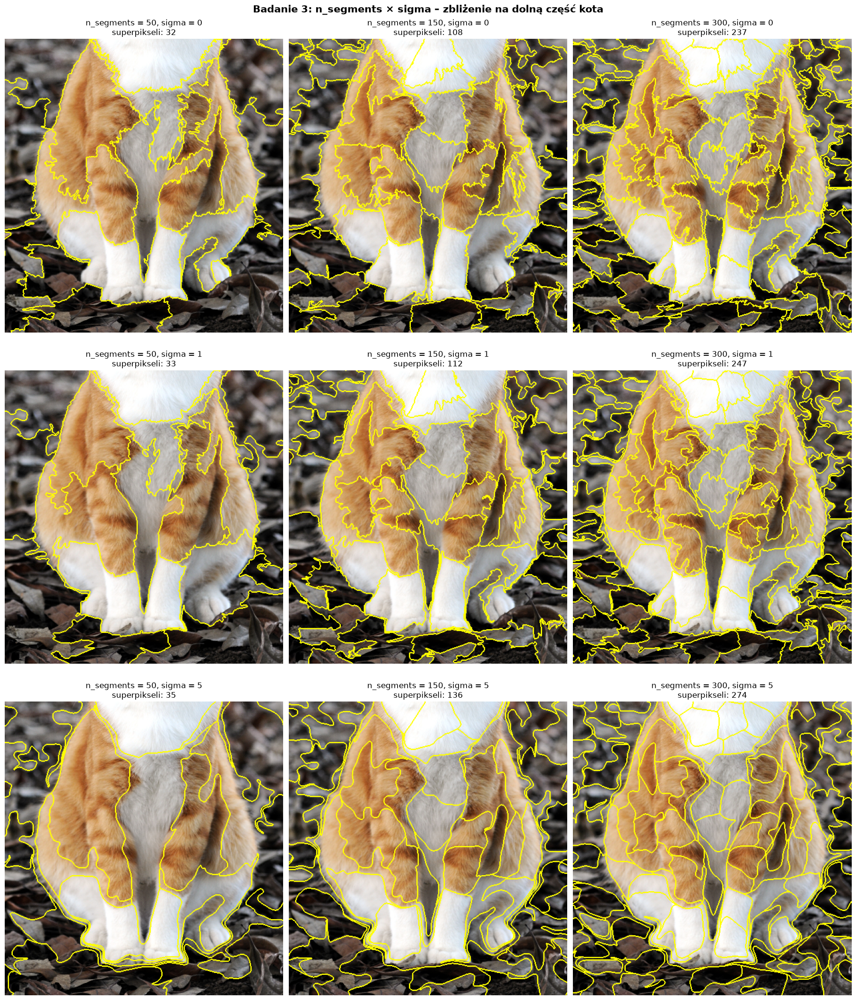

In [30]:
badaj_slic(tabby, 'Badanie 3: n_segments × sigma – zbliżenie na dolną część kota',
           [dict(n_segments=n, sigma=s) for s in [0, 1, 5] for n in [50, 150, 300]],
           wycinek=(380, 854, 150, 600))

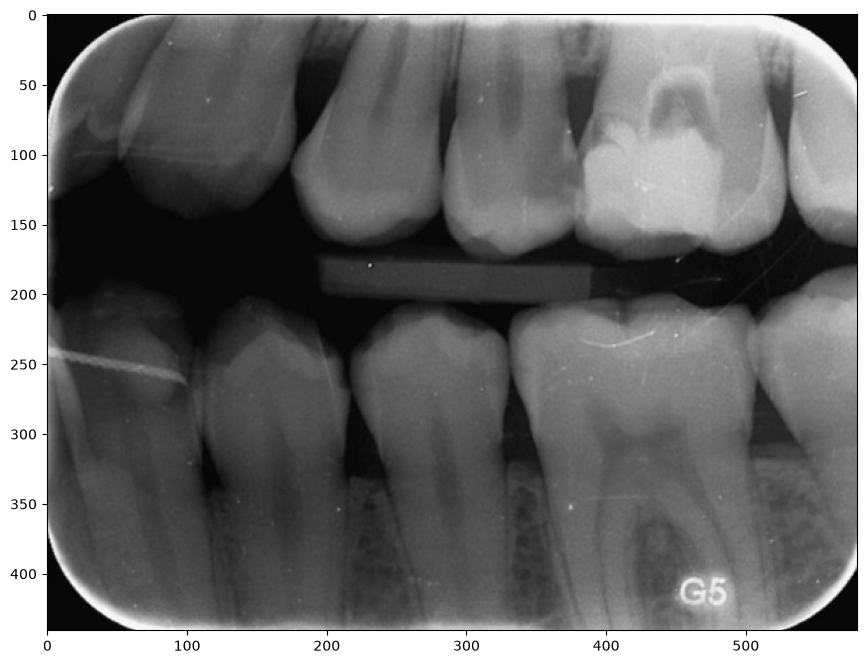

In [31]:
caries = cv2.imread('../Materialy/roboflow-caries-117.jpg')[..., 0]
plt.subplots(1,1,figsize=(12,8))[1].imshow(caries, cmap='gray');

Rozwiązanie – `caries`:

Obraz szary ma jasność w zakresie [0, 1], a nie 0–100 jak składowa L w Lab, więc `compactness` musi być ok. 100× mniejsze niż domyślne 10. Przyjęto `compactness = 0.05`.

**Badanie 1: `n_segments`** – `sigma = 0`

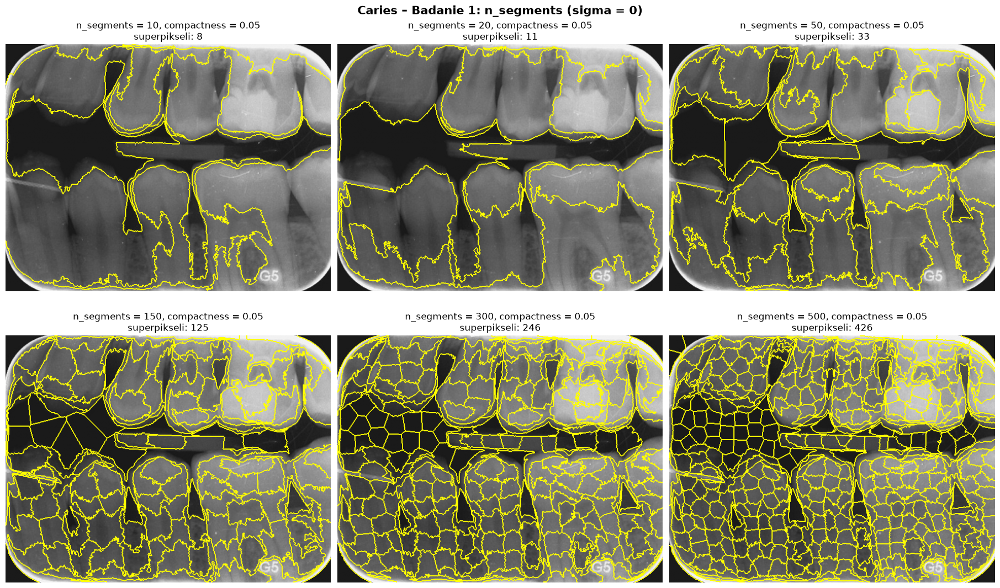

In [32]:
badaj_slic(caries, 'Caries – Badanie 1: n_segments (sigma = 0)',
           [dict(n_segments=n, compactness=0.05) for n in [10, 20, 50, 150, 300, 500]])

**Badanie 2: `sigma`** – `n_segments = 100`

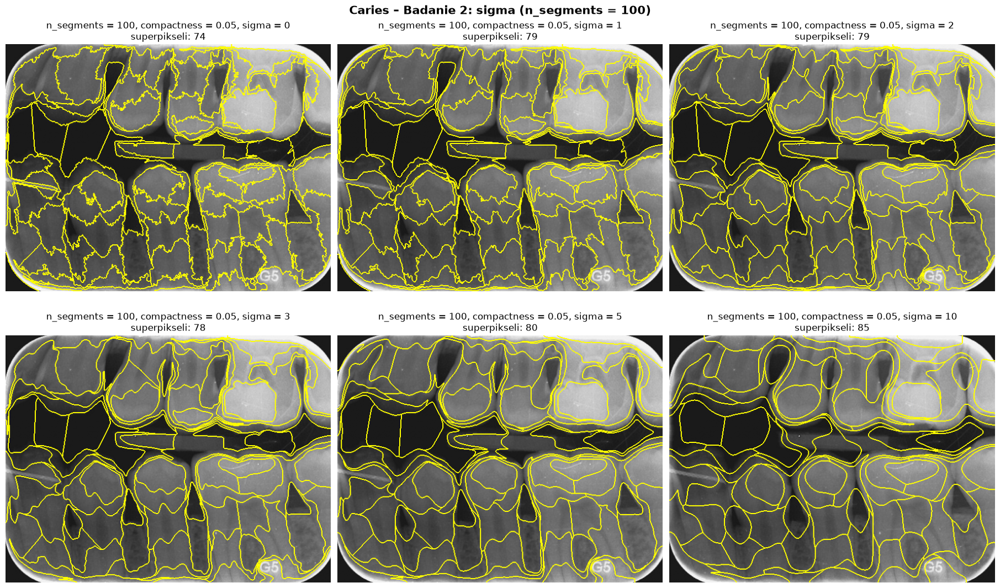

In [33]:
badaj_slic(caries, 'Caries – Badanie 2: sigma (n_segments = 100)',
           [dict(n_segments=100, compactness=0.05, sigma=s) for s in [0, 1, 2, 3, 5, 10]])

**Badanie 3: `n_segments` × `sigma` – zbliżenie na lewe dolne zęby** – korony, ciemne szczeliny między zębami i korzenie na tle kości. Wiersze: `sigma` = 0, 1, 5; kolumny: `n_segments` = 20, 100, 200.

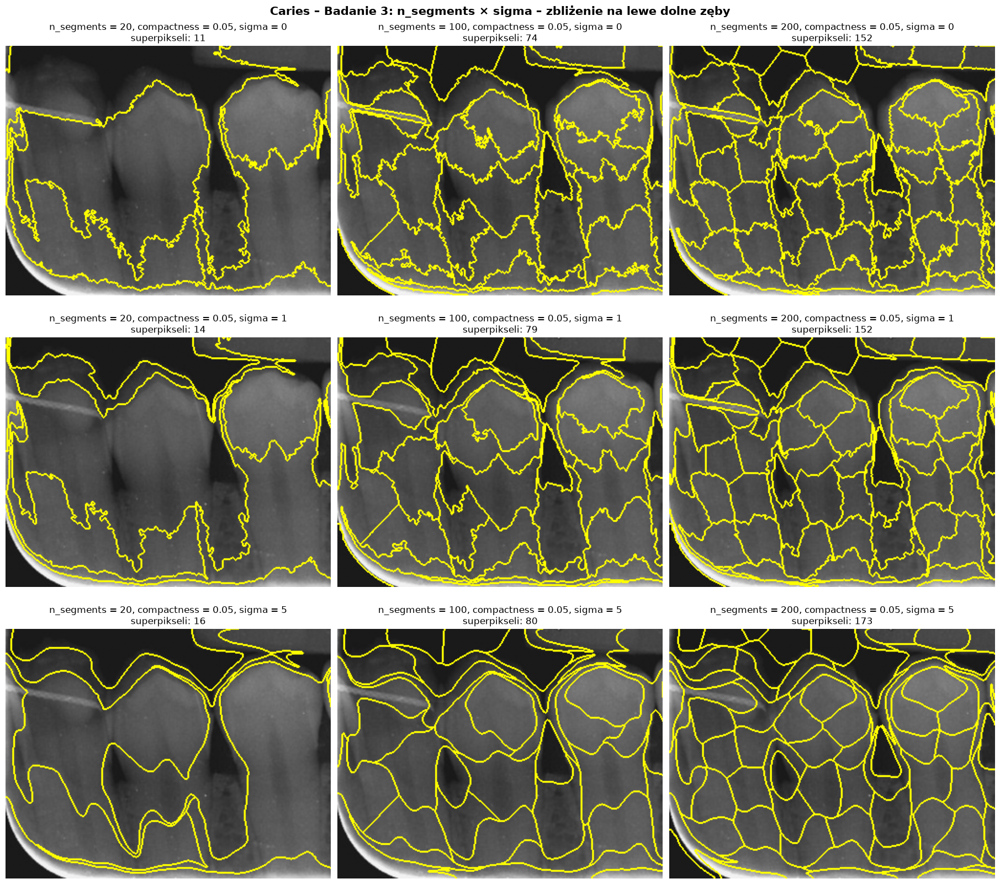

In [34]:
badaj_slic(caries, 'Caries – Badanie 3: n_segments × sigma – zbliżenie na lewe dolne zęby',
           [dict(n_segments=n, compactness=0.05, sigma=s) for s in [0, 1, 5] for n in [20, 100, 200]],
           wycinek=(180, 441, 0, 340))

**Wnioski**

Wspólne dla obu obrazów:
- **`n_segments`** – przy małej liczbie superpiksele są duże i obejmują obiekt razem z tłem. Więcej superpikseli dokładniej odwzorowuje kontury, ale powyżej ok. 400 jednolite obszary są już tylko rozdrabniane. Faktycznie superpikseli jest mniej niż `n_segments`, bo małe fragmenty są doklejane do sąsiadów.
- **`sigma`** – lekkie rozmycie usuwa teksturę i szum, więc granice są gładsze i nadal trzymają się konturów. Zbyt duże rozmywa też krawędzie obiektów i granice zaczynają się z nimi rozjeżdżać.

Kot (`tabby`):
- Głównym problemem jest tekstura (liście, pręgi futra) i słaby kontrast białych łap z jasnymi liśćmi – np. przy `n_segments = 200, sigma = 0` prawa tylna łapa zlewa się z liściem, a `sigma = 1` to naprawia. Przy `sigma` ≥ 5 superpiksele wzdłuż konturu zabierają pasek tła.
- Najlepiej: `n_segments` ≈ 200–400, `sigma` ≈ 1–2.

Zęby (`caries`):
- Korony na tle ciemnych szczelin mają duży kontrast i są dobrze odwzorowane już przy małej liczbie superpikseli. Najtrudniejsze są korzenie na tle kości o podobnej jasności – tam superpiksele mieszane zostają nawet przy dużym `n_segments`.
- Zęby są duże i gładkie, więc znoszą mocniejsze rozmycie niż kot, a `sigma` dobrze usuwa szum zdjęcia RTG. Dopiero przy `sigma` ≥ 5 cienka płytka między łukami zębowymi traci kształt, a przy 10 jej superpiksele obejmują też ciemne tło.

#### Zadanie 2

Wykonaj segmentację wododziałową dla obrazów `tabby` i `caries` za pomocą funkcji [`cv2.watershed`](https://docs.opencv.org/4.x/d3/d47/group__imgproc__segmentation.html#ga3267243e4d3f95165d55a618c65ac6e1). Implementacja OpenCV przyjmuje dwa argumenty: obraz wejściowy (8-bit, 3 kanały) i obraz wyjściowy (32-bit, 1 kanał).

Uwaga: obraz wyjściowy musi zawierać oznaczenia początkowe segmentów (_markery_) - to znaczy, że musisz zacząć od przygotowania macierzy markerów. Poprawnie przygotowana macierz zawiera $N$ markerów, tj. pikseli oznaczonych liczbami całkowitymi od 1 do $N$, a wartość pozostałych pikseli wynosi 0. Piksele zerowe zostaną przyporządkowane do grup dookoła markerów.

Sugerowane metody przygotowania markerów (wybierz dwie i porównaj):
* równomierna siatka
* lokalne minima jasności
* manualnie wybrane centra (_segmentacja interaktywna_)

Rozwiązanie:

`cv2.watershed` zalewa obraz od markerów: do regionów dołączane są kolejno piksele najmniej różniące się kolorem od sąsiada, który już do regionu należy. Regiony rosną więc przez obszary jednolite, a granice (wartość −1) powstają na najsilniejszych krawędziach między markerami. Segmentów jest zawsze tyle, ile markerów.

- `markery_siatka` – markery co `krok` pikseli w obu kierunkach.
- `markery_minima` – markery w lokalnych minimach jasności: piksel jest minimum, jeśli jest równy minimum w oknie `okno`×`okno` (erozja = filtr minimum) i należy do minimum regionalnego (`local_minima` – wszyscy sąsiedzi obszaru są jaśniejsi). Bez tego drugiego warunku płaskie fragmenty tła, z których dalej jest gdzieś ciemniej, dawały fałszywe, prostokątne markery. Parzyste okno jest powiększane o 1, żeby było wyśrodkowane. Sąsiadujące piksele minimum tworzą jeden marker. Obraz jest wcześniej rozmywany (`sigma = 3`) – bez tego minima wypadają na szumie i teksturze (dla `tabby` przy oknie 40 jest ich ok. 2,4× więcej).
- `markery_reczne` – ręcznie wybrane punkty (y, x), osobna lista dla każdej klasy.
- `badaj_watershed` – jak `badaj_slic`: każdy wariant markerów to osobny obrazek (maks. 3 w wierszu), czerwone punkty to markery.

In [35]:
def markery_siatka(img, krok):
    markery = np.zeros(img.shape[:2], dtype=np.int32)
    wezly = markery[krok // 2::krok, krok // 2::krok]  # widok na węzły siatki
    wezly[:] = np.arange(1, wezly.size + 1).reshape(wezly.shape)
    return markery


def markery_minima(img, okno, sigma=3):
    # lokalne minimum = piksel równy minimum w oknie okno x okno (erozja to filtr minimum)
    szary = (img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)).astype(np.float32)
    if sigma > 0:
        szary = cv2.GaussianBlur(szary, (0, 0), sigma)
    okno = okno // 2 * 2 + 1  # nieparzyste okno, żeby było wyśrodkowane na pikselu
    minima = szary == cv2.erode(szary, np.ones((okno, okno), np.uint8))
    minima &= local_minima(szary, connectivity=2)  # odrzuca płaskie fragmenty, z których dalej jest ciemniej
    _, markery = cv2.connectedComponents(minima.astype(np.uint8))  # sąsiadujące piksele minimum -> jeden marker
    return markery


def markery_reczne(img, punkty, promien=6):
    # punkty: [[(y, x), ...] klasy 1, [(y, x), ...] klasy 2, ...] – każdy punkt to koło z etykietą swojej klasy
    markery = np.zeros(img.shape[:2], dtype=np.int32)
    for etykieta, lista in enumerate(punkty, start=1):
        for y, x in lista:
            cv2.circle(markery, (x, y), promien, etykieta, -1)
    return markery


def badaj_watershed(img, tytul, warianty, kolumny=3, szer=6):
    # warianty: {opis: macierz markerów} – każdy wariant to osobne wywołanie watershed i osobny obrazek
    kolorowy = img if img.ndim == 3 else cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)  # watershed wymaga 3 kanałów
    kolumny = min(kolumny, len(warianty))
    wiersze = int(np.ceil(len(warianty) / kolumny))
    wys = szer * img.shape[0] / img.shape[1] + 0.6  # + miejsce na tytuł
    _, axs = plt.subplots(wiersze, kolumny, figsize=(szer * kolumny, wys * wiersze + 0.5), squeeze=False, layout='constrained')
    for ax in axs.flat:
        ax.axis('off')
    for ax, (opis, markery) in zip(axs.flat, warianty.items()):
        segmenty = cv2.watershed(kolorowy, markery.copy())  # watershed nadpisuje markery wynikiem
        wynik = mark_boundaries(kolorowy, segmenty)
        wynik[cv2.dilate((markery > 0).astype(np.uint8), np.ones((5, 5), np.uint8)) > 0] = (1, 0, 0)
        ax.imshow(wynik)
        ax.set_title(f'{opis}\nsegmentów: {markery.max()}')
    plt.suptitle(tytul, fontsize=15, fontweight='bold')
    plt.show()

**Tabby – siatka vs minima jasności** – górny wiersz: siatka (`krok` = 120, 60, 30 px), dolny: minima (`okno` = 100, 40, 15 px). W kolejnych kolumnach markerów jest coraz więcej.

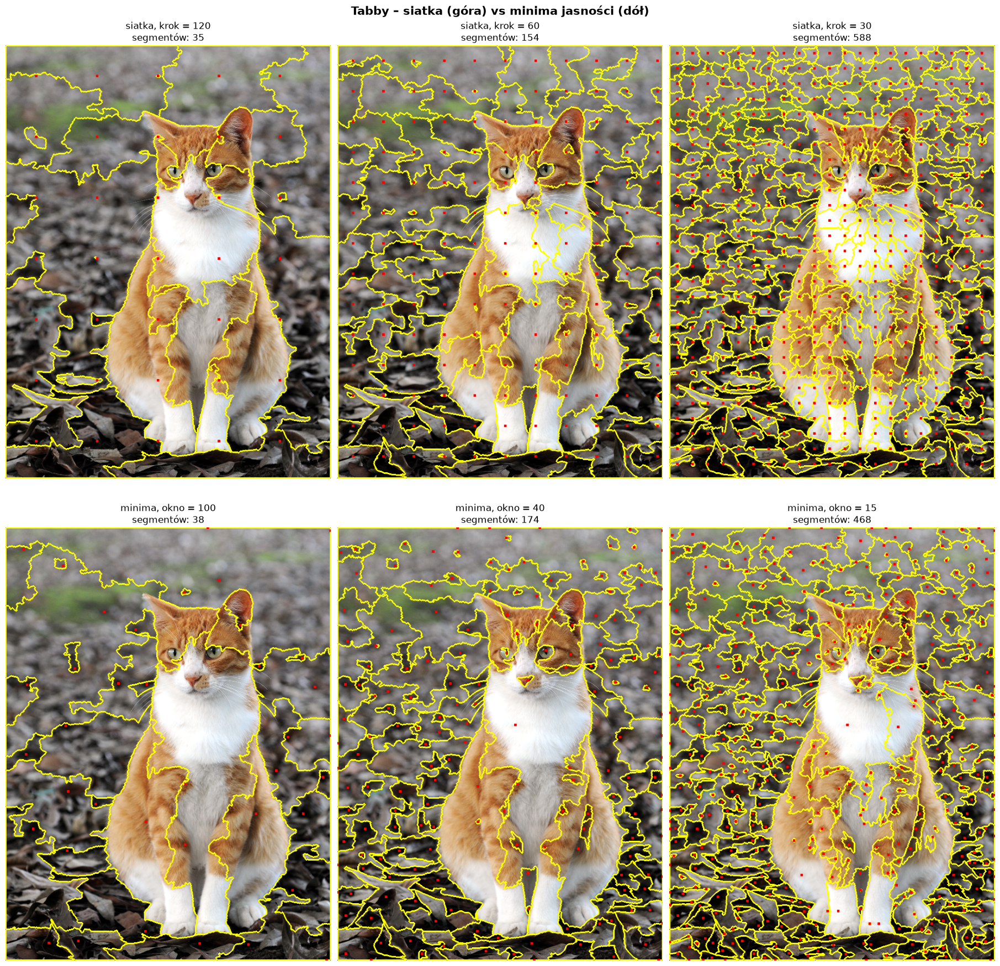

In [36]:
badaj_watershed(tabby, 'Tabby – siatka (góra) vs minima jasności (dół)',
                {f'siatka, krok = {k}': markery_siatka(tabby, k) for k in [120, 60, 30]}
                | {f'minima, okno = {o}': markery_minima(tabby, o) for o in [100, 40, 15]})

**Caries – siatka vs minima jasności** – siatka jak wyżej (`krok` = 120, 60, 30 px), minima: `okno` = 100, 40, 20 px.

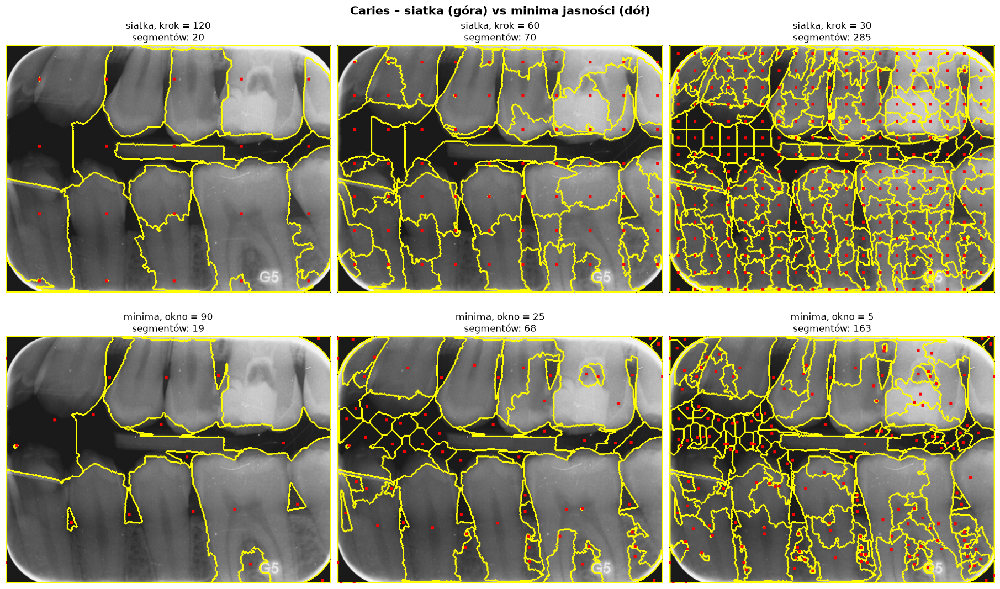

In [47]:
badaj_watershed(caries, 'Caries – siatka (góra) vs minima jasności (dół)',
                {f'siatka, krok = {k}': markery_siatka(caries, k) for k in [120, 60, 30]}
                | {f'minima, okno = {o}': markery_minima(caries, o) for o in [90, 25, 5]})

**Tabby – manualnie wybrane centra** – markery klasy 1 leżą na kocie, klasy 2 na tle, więc wynikiem są tylko dwa segmenty: kot i tło. A – po jednym punkcie, B – więcej punktów, także w trudnych miejscach (uszy, łapy, liście przy łapach).

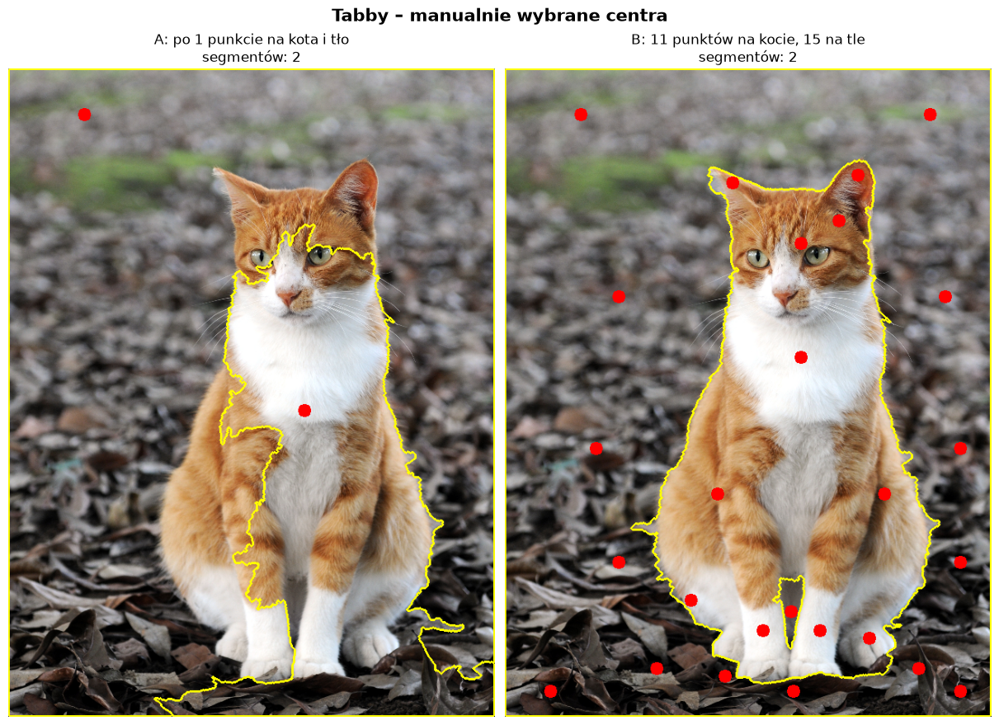

In [38]:
kot_A, tlo_A = [(450, 390)], [(60, 100)]
kot_B = [(150, 300), (140, 465), (200, 440), (230, 390), (380, 390), (560, 280), (560, 500),
         (740, 340), (740, 415), (700, 245), (750, 480)]
tlo_B = [(60, 100), (60, 560), (300, 150), (300, 580), (500, 120), (500, 600), (650, 150), (650, 600),
         (790, 200), (800, 290), (820, 60), (820, 600), (820, 380), (715, 377), (790, 545)]
badaj_watershed(tabby, 'Tabby – manualnie wybrane centra',
                {'A: po 1 punkcie na kota i tło': markery_reczne(tabby, [kot_A, tlo_A]),
                 'B: 11 punktów na kocie, 15 na tle': markery_reczne(tabby, [kot_B, tlo_B])})

**Wnioski**

- **Siatka** – markery leżą równo, niezależnie od treści obrazu, a watershed (w odróżnieniu od SLIC) nie ogranicza kształtu regionów, więc są one bardzo nieregularne i poszarpane przez teksturę. Obiekty są cięte w przypadkowych miejscach, a część regionów jest mieszana (np. przy `krok = 60` prawa tylna łapa kota łączy się z liśćmi). Gęsta siatka zmniejsza ten problem kosztem ogromnej nadsegmentacji. Na zębach w płaskim czarnym tle (brak krawędzi) regiony są niemal kwadratami siatki.
- **Minima jasności** – markery dopasowują się do treści: leżą w ciemnych miejscach (liście, pręgi, oczy, szczeliny między zębami, ciemniejsze wnętrza zębów). Jasne, jednolite obiekty dostają mało markerów i są pokryte kilkoma dużymi regionami trzymającymi się konturu – na `caries` regiony w przybliżeniu odpowiadają pojedynczym zębom (korzenie zlewają się jednak z kością). Wada: fragment obiektu bez własnego minimum zostaje zalany z sąsiedniego markera – np. prawe ucho kota łączy się z tłem.
- Przy podobnej liczbie markerów minima dają bardziej jednolite segmenty niż siatka, bo korzystają z budowy obrazu (jasne obiekty na ciemniejszym tle). Dla zębów różnica jest wyraźna.

---

#### Zadanie dodatkowe (dla chętnych, bez oceny)

Dla obrazu `tabby` wykonaj post-processing wybranej metody segmentacji by uzyskać dwa jednorodne obszary: jeden zawierający wyłącznie kota, drugi zawierający wyłącznie tło.

Można to zadanie potraktować jako binaryzację na poziomie superpikseli i zrealizować je za pomocą progowania. 
Można też potraktować je jako klasteryzację superpikseli i wykorzystać np. [`cv2.kmeans`](https://docs.opencv.org/4.x/d5/d38/group__core__cluster.html#ga9a34dc06c6ec9460e90860f15bcd2f88).  
Niezależnie od wybranej ścieżki, konieczne będzie:
1. dobranie odpowiednich (czyli jakich?) parametrów algorytmu segmentacji,
2. opisanie każdego z superpikseli za pomocą jakiejś *cechy/cech* (jakich?), opisującej semantykę rejonów, tak aby na tej podstawie dokonać klasyfikacji.

In [39]:
# zacznij od przygotowania macierzy wejściowej (data) reprezentującej superpiksele jako punkty danych